In [ ]:
from pathlib import Path
import os
import subprocess
import sys

venv_dir = Path(".venv")
venv_python = venv_dir / ("Scripts/python.exe" if os.name == "nt" else "bin/python")

if not venv_python.exists():
    subprocess.check_call([sys.executable, "-m", "venv", str(venv_dir)])

subprocess.check_call([
    str(venv_python),
    "-m",
    "pip",
    "install",
    "numpy",
    "pandas",
    "matplotlib",
    "scipy",
    "ipykernel",
])
subprocess.check_call([
    str(venv_python),
    "-m",
    "ipykernel",
    "install",
    "--user",
    "--name",
    "statystyka-lab-1",
    "--display-name",
    "Python (Statystyka Lab 1)",
])

print("Środowisko .venv jest gotowe.")
print("Wybierz kernel: Python (Statystyka Lab 1), aby uruchamiać notebook w tym środowisku.")


# Zadanie 1


Wyniki dla n = 20, theta = 0, sigma = 1:
Estymator            | Obciążenie   | Wariancja    | MSE          | Diff        
---------------------------------------------------------------------------
1                    | -0.0065      | 0.0501       | 0.0502       | 0.0000      
2                    | -0.0070      | 0.0721       | 0.0721       | 0.0000      
3                    | -0.0058      | 0.0647       | 0.0647       | 0.0000      
4                    | 0.9271       | 0.0235       | 0.8830       | 0.0000      
5                    | -5.8333      | 432575.9470  | 432609.9738  | 0.0000      
6                    | -0.0187      | 0.6768       | 0.6772       | 0.0000      
7                    | 1.2548       | 0.0473       | 1.6217       | 0.0000      

Wyniki dla n = 50, theta = 0, sigma = 1:
Estymator            | Obciążenie   | Wariancja    | MSE          | Diff        
---------------------------------------------------------------------------
1                    | 0.0004      

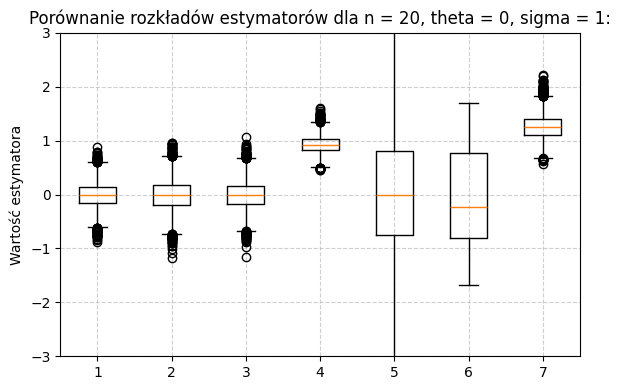

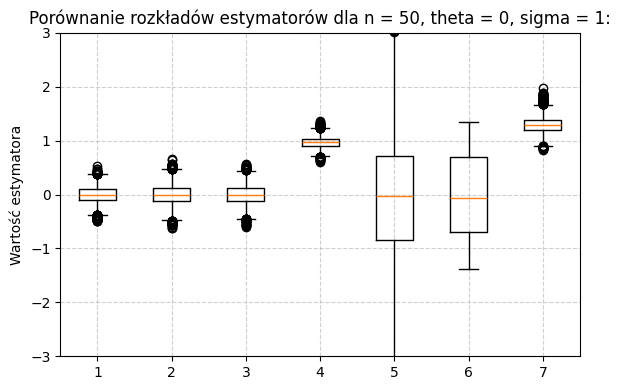

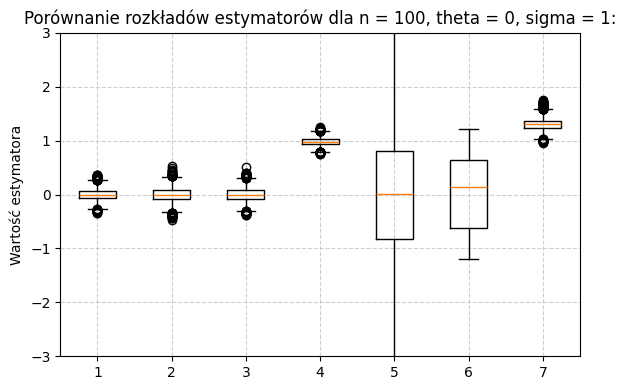

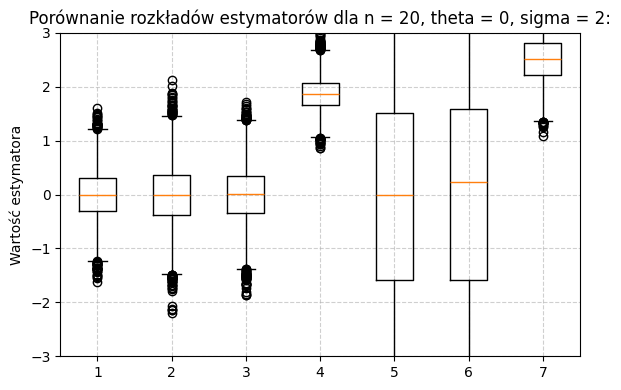

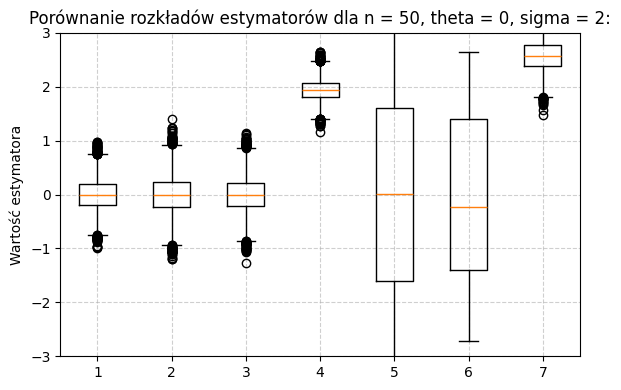

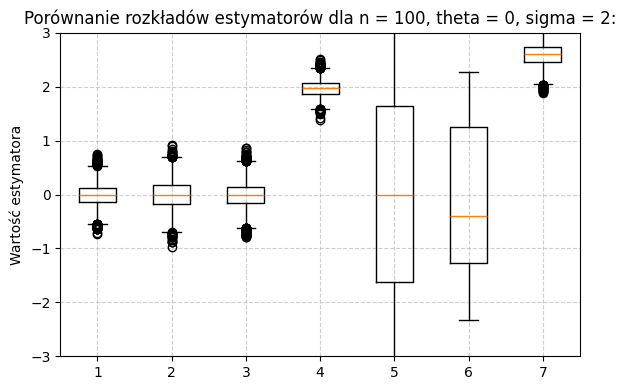

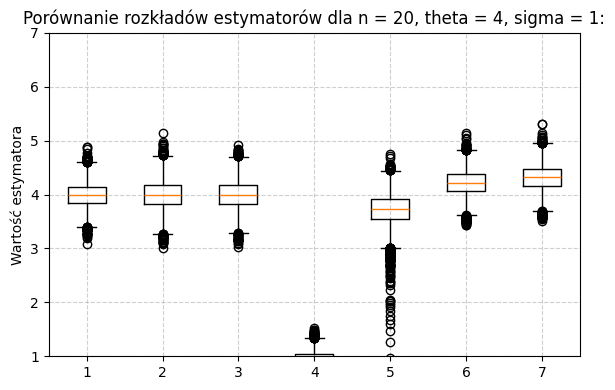

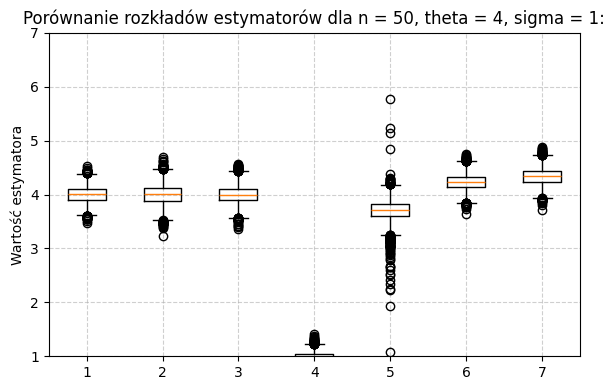

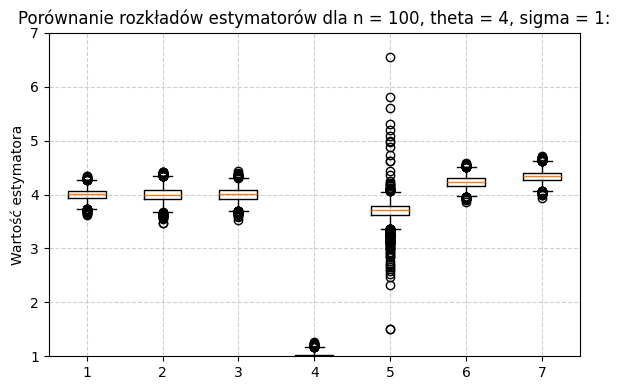

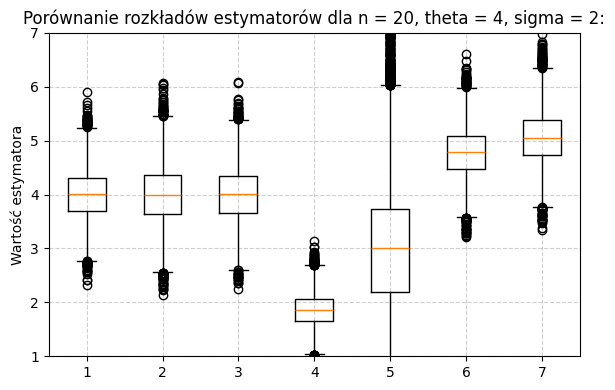

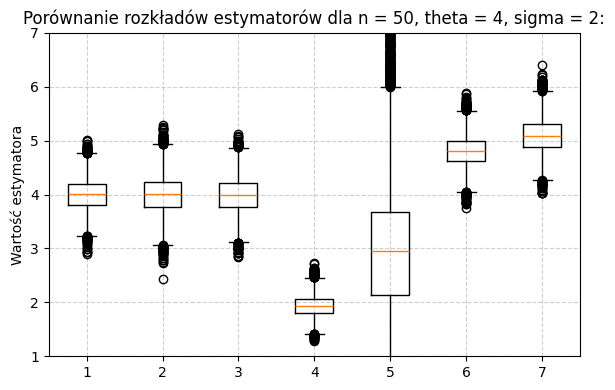

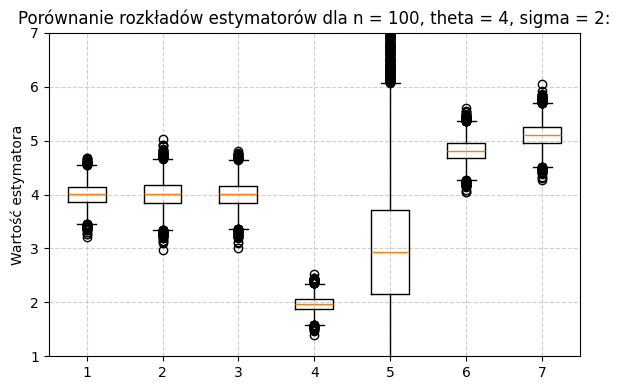

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

def estimator_1(x):
    return np.mean(x)

def estimator_2(x):
    return np.median(x)

def estimator_3(x):
    weights = np.arange(1, len(x) + 1)
    weights = weights / np.sum(weights)
    return np.sum(x * weights)

def estimator_4(x):
    n = len(x)
    x_sorted = np.sort(x)
    i = np.arange(1, n + 1)
    weights = norm.pdf(norm.ppf((i - 1) / n)) - norm.pdf(norm.ppf(i / n))

    return np.sum(x_sorted * weights)

def estimator_5(x):
    return len(x) / (np.sum(1 / x))

def estimator_6(x):
    return np.cbrt(1 / len(x) * np.sum(x ** 3))

def estimator_7(x):
    return (1 / len(x) * np.sum(x ** 4)) ** (1/4)


n_values =  [20, 50, 100]
k = 10_000
labels = ['1', '2', '3', '4', '5', '6', '7']

cases = [
    (0, 1),
    (0, 2),
    (4, 1),
    (4, 2)
]

for theta, sigma in cases:
    for n in n_values:
        samples = np.random.normal(loc=theta, scale=sigma, size=(k, n))

        est_vals = [
            np.apply_along_axis(estimator_1, axis=1, arr=samples),
            np.apply_along_axis(estimator_2, axis=1, arr=samples),
            np.apply_along_axis(estimator_3, axis=1, arr=samples),
            np.apply_along_axis(estimator_4, axis=1, arr=samples),
            np.apply_along_axis(estimator_5, axis=1, arr=samples),
            np.apply_along_axis(estimator_6, axis=1, arr=samples),
            np.apply_along_axis(estimator_7, axis=1, arr=samples),
        ]
        fig, ax = plt.subplots(figsize=(6, 4))

        print(f"\nWyniki dla n = {n}, theta = {theta}, sigma = {sigma}:")
        print(f"{'Estymator':<20} | {'Obciążenie':<12} | {'Wariancja':<12} | {'MSE':<12} | {'Diff':<12}")
        print("-" * 75)

        for i, est_val in enumerate(est_vals):
            bias = np.mean(est_val) - theta
            variance = np.var(est_val)
            mse = np.mean((est_val -theta) ** 2)
            diff = np.abs(mse - bias ** 2 - variance)
            print(f"{labels[i]:<20} | {bias:<12.4f} | {variance:<12.4f} | {mse:<12.4f} | {diff:<12.4f}")

        ax.boxplot(est_vals, tick_labels=labels)
        ax.set_title(f'Porównanie rozkładów estymatorów dla n = {n}, theta = {theta}, sigma = {sigma}:')
        ax.set_ylabel('Wartość estymatora')
        ax.grid(True, linestyle='--', alpha=0.6)
        ax.set_ylim(-3 + theta, 3 + theta)
        plt.tight_layout()

plt.show()

# Zadanie 2


Wyniki dla n = 50, theta = 0, sigma = 1:
Estymator            | Obciążenie   | Wariancja    | MSE          | Diff        
---------------------------------------------------------------------------
1                    | 0.0006       | 0.0202       | 0.0202       | 0.0000      
2                    | 0.0024       | 0.0308       | 0.0308       | 0.0000      

Wyniki dla n = 50, theta = 0, sigma = 2:
Estymator            | Obciążenie   | Wariancja    | MSE          | Diff        
---------------------------------------------------------------------------
1                    | -0.0012      | 0.0815       | 0.0815       | 0.0000      
2                    | -0.0017      | 0.1243       | 0.1243       | 0.0000      

Wyniki dla n = 50, theta = 4, sigma = 1:
Estymator            | Obciążenie   | Wariancja    | MSE          | Diff        
---------------------------------------------------------------------------
1                    | -0.0015      | 0.0201       | 0.0201       | 0.0000     

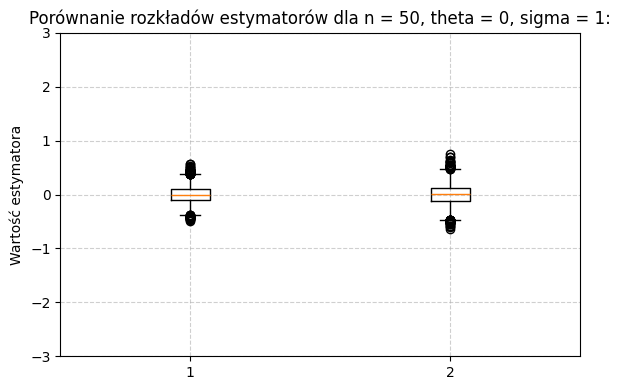

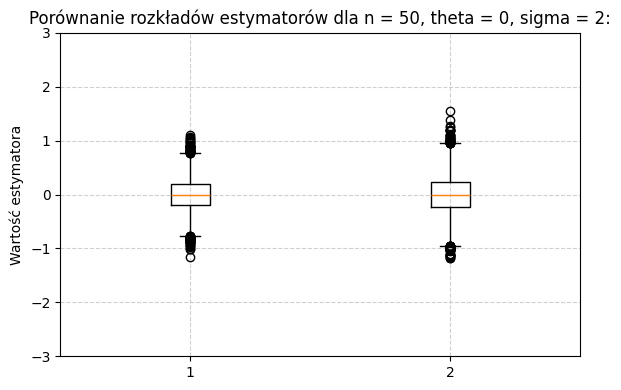

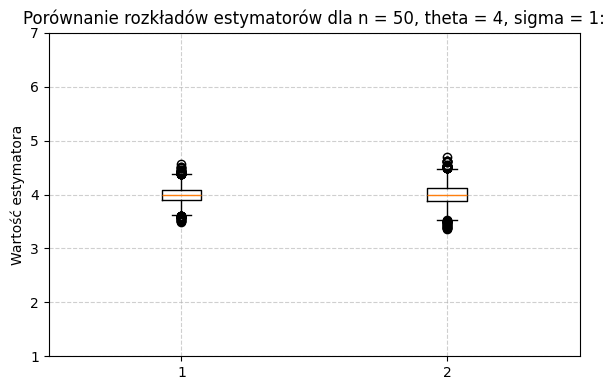

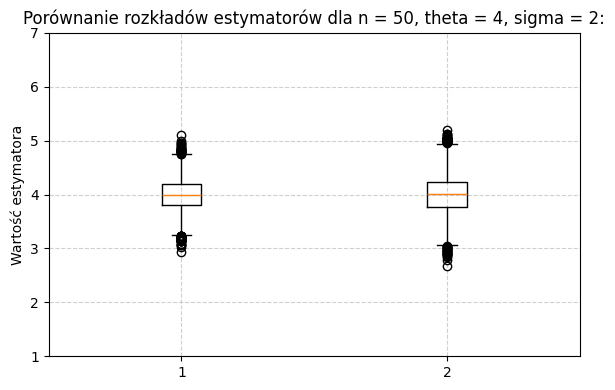


Wyniki dla n = 50, theta = 0, sigma = 1:
Estymator            | Obciążenie   | Wariancja    | MSE          | Diff        
---------------------------------------------------------------------------
1                    | 0.0022       | 0.0652       | 0.0652       | 0.0000      
2                    | 0.0001       | 0.0795       | 0.0795       | 0.0000      

Wyniki dla n = 50, theta = 0, sigma = 2:
Estymator            | Obciążenie   | Wariancja    | MSE          | Diff        
---------------------------------------------------------------------------
1                    | 0.0012       | 0.2600       | 0.2600       | 0.0000      
2                    | -0.0009      | 0.3098       | 0.3098       | 0.0000      

Wyniki dla n = 50, theta = 4, sigma = 1:
Estymator            | Obciążenie   | Wariancja    | MSE          | Diff        
---------------------------------------------------------------------------
1                    | -0.0003      | 0.0635       | 0.0635       | 0.0000     

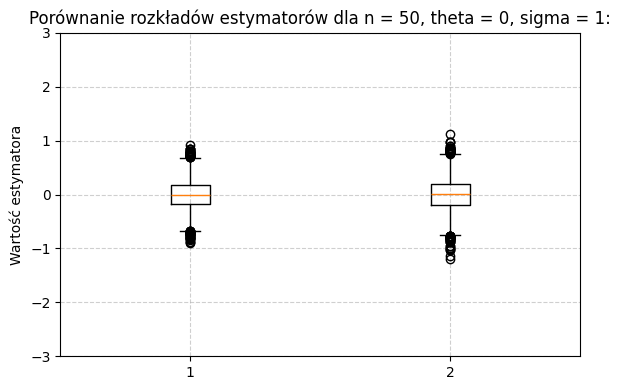

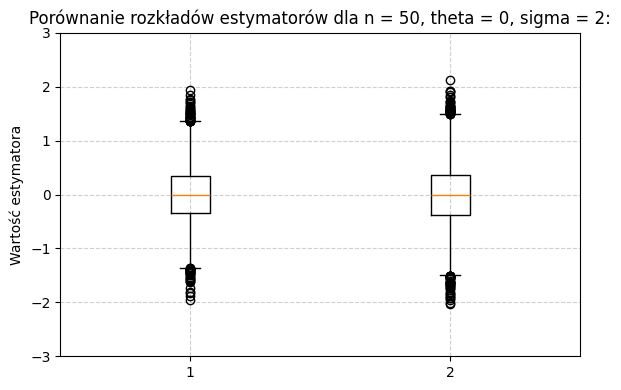

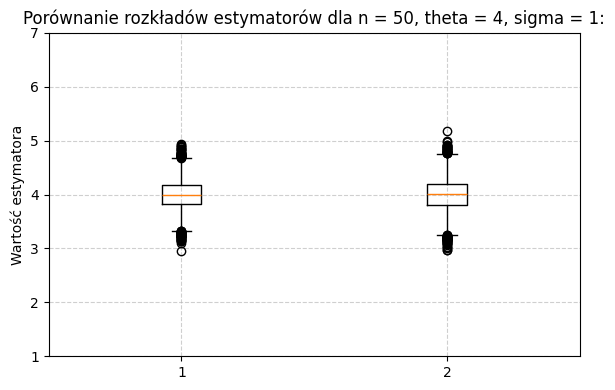

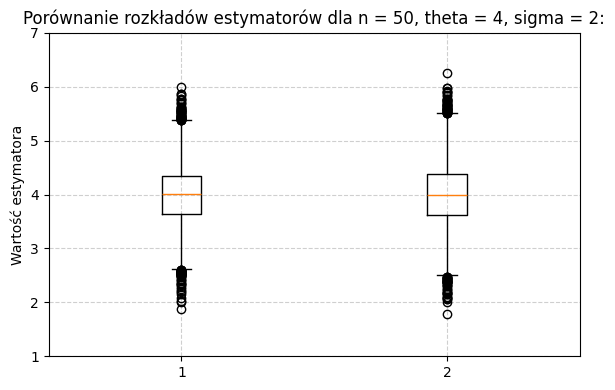


Wyniki dla n = 50, theta = 0, sigma = 1:
Estymator            | Obciążenie   | Wariancja    | MSE          | Diff        
---------------------------------------------------------------------------
1                    | 0.3357       | 1947.8307    | 1947.9434    | 0.0000      
2                    | -0.0004      | 0.0518       | 0.0518       | 0.0000      

Wyniki dla n = 50, theta = 0, sigma = 2:
Estymator            | Obciążenie   | Wariancja    | MSE          | Diff        
---------------------------------------------------------------------------
1                    | -15.1405     | 2332670.2940 | 2332899.5293 | 0.0000      
2                    | 0.0030       | 0.2013       | 0.2013       | 0.0000      

Wyniki dla n = 50, theta = 4, sigma = 1:
Estymator            | Obciążenie   | Wariancja    | MSE          | Diff        
---------------------------------------------------------------------------
1                    | -9.9567      | 659619.1671  | 659718.3030  | 0.0000     

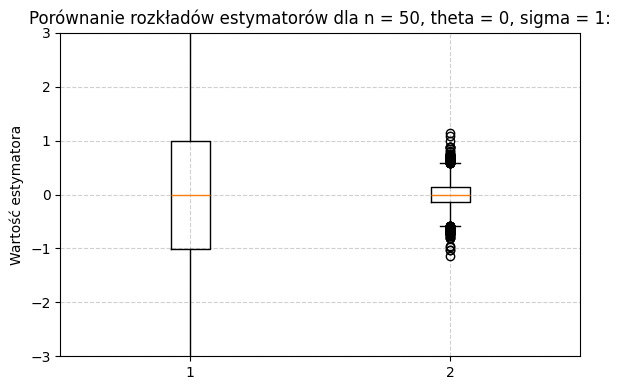

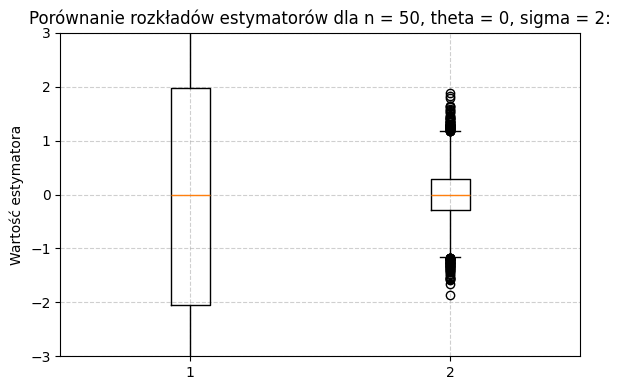

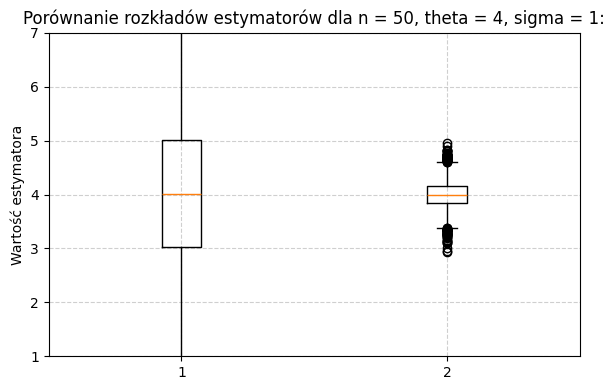

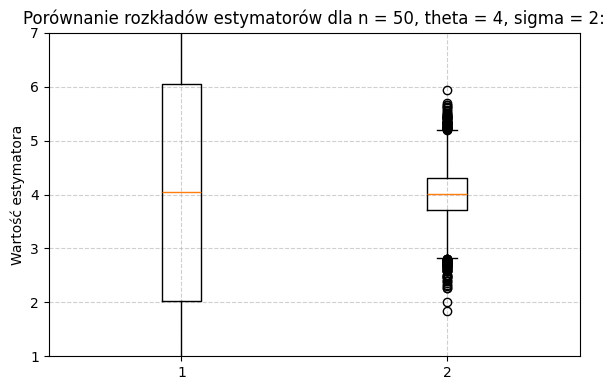

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

def estimator_1(x):
    return np.mean(x)

def estimator_2(x):
    return np.median(x)

n = 50
k = 10_000
labels = ['1', '2']

cases = [
    (0, 1),
    (0, 2),
    (4, 1),
    (4, 2)
]

def eval(cases, distribution):
    for theta, sigma in cases:
        if distribution == 'normal':
            samples = np.random.normal(loc=theta, scale=sigma, size=(k, n))
        elif distribution == 'logistic':
            samples = np.random.logistic(loc=theta, scale=sigma, size=(k, n))
        elif distribution == 'cauchy':
            samples = theta + sigma * np.random.standard_cauchy(size=(k, n))

        est_vals = [
            np.apply_along_axis(estimator_1, axis=1, arr=samples),
            np.apply_along_axis(estimator_2, axis=1, arr=samples)
        ]
        fig, ax = plt.subplots(figsize=(6, 4))

        print(f"\nWyniki dla n = {n}, theta = {theta}, sigma = {sigma}:")
        print(f"{'Estymator':<20} | {'Obciążenie':<12} | {'Wariancja':<12} | {'MSE':<12} | {'Diff':<12}")
        print("-" * 75)

        for i, est_val in enumerate(est_vals):
            bias = np.mean(est_val) - theta
            variance = np.var(est_val)
            mse = np.mean((est_val -theta) ** 2)
            diff = np.abs(mse - bias ** 2 - variance)
            print(f"{labels[i]:<20} | {bias:<12.4f} | {variance:<12.4f} | {mse:<12.4f} | {diff:<12.4f}")

        ax.boxplot(est_vals, tick_labels=labels)
        ax.set_title(f'Porównanie rozkładów estymatorów dla n = {n}, theta = {theta}, sigma = {sigma}:')
        ax.set_ylabel('Wartość estymatora')
        ax.grid(True, linestyle='--', alpha=0.6)
        ax.set_ylim(-3 + theta, 3 + theta)
        plt.tight_layout()
    plt.show()

eval(cases, 'normal')
eval(cases, 'logistic')
eval(cases, 'cauchy')

# Zadanie 3

Wyniki dla średniej:

k        | Obciążenie   | Wariancja    | MSE          | Diff        
--------------------------------------------------------------------
10       | 0.1993       | 0.0196       | 0.0593       | 0.0000      
20       | 0.3991       | 0.0196       | 0.1789       | 0.0000      
30       | 0.5999       | 0.0195       | 0.3795       | 0.0000      
40       | 0.8012       | 0.0199       | 0.6619       | 0.0000      
50       | 1.0004       | 0.0197       | 1.0204       | 0.0000      
60       | 1.1981       | 0.0192       | 1.4546       | 0.0000      
70       | 1.4001       | 0.0198       | 1.9801       | 0.0000      
80       | 1.5998       | 0.0200       | 2.5793       | 0.0000      
90       | 1.7998       | 0.0191       | 3.2585       | 0.0000      
100      | 1.9975       | 0.0195       | 4.0097       | 0.0000      

Wyniki dla mediany:

k        | Obciążenie   | Wariancja    | MSE          | Diff        
-----------------------------------------------------------

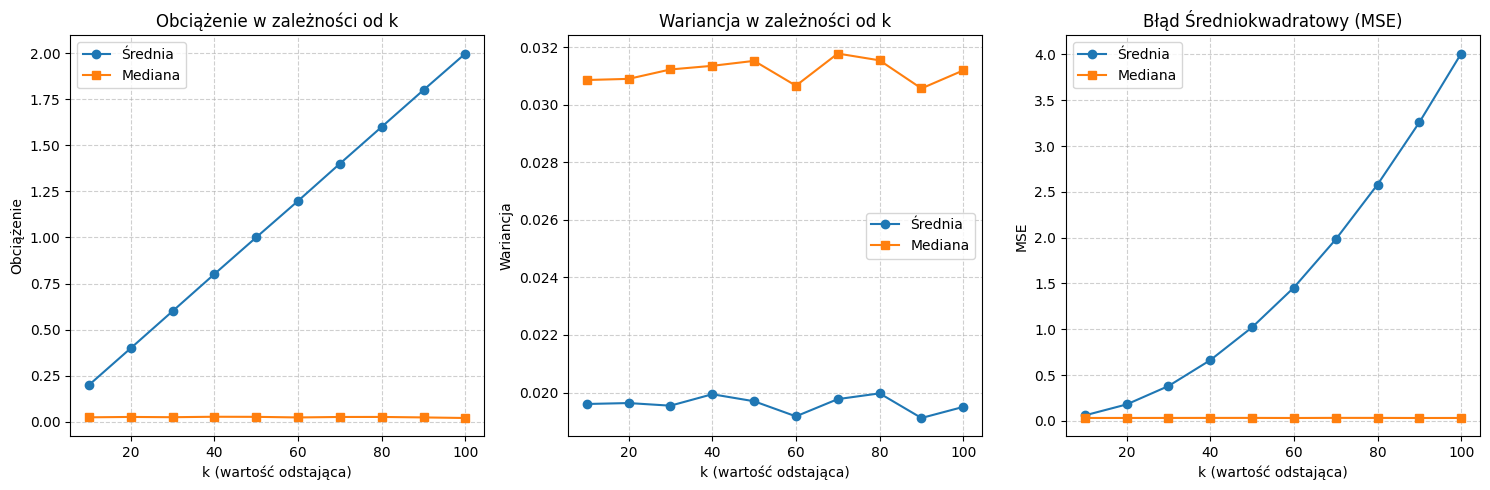

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def estimator_1(x):
    return np.mean(x)

def estimator_2(x):
    return np.median(x)

n = 50
repetitions = 10_000
theta = 0
sigma = 1

k_values = np.arange(10, 101, 10)

bias_1, var_1, mse_1 = [], [], []
bias_2, var_2, mse_2 = [], [], []

for k in k_values:
    samples_base = np.random.normal(loc=theta, scale=sigma, size=(repetitions, n - 1))

    outliers = np.full((repetitions, 1), k)
    samples = np.hstack((samples_base, outliers))

    est_1_vals = np.apply_along_axis(estimator_1, axis=1, arr=samples)
    est_2_vals = np.apply_along_axis(estimator_2, axis=1, arr=samples)

    b1 = np.mean(est_1_vals) - theta
    v1 = np.var(est_1_vals)
    m1 = np.mean((est_1_vals - theta) ** 2)
    bias_1.append(b1)
    var_1.append(v1)
    mse_1.append(m1)

    b2 = np.mean(est_2_vals) - theta
    v2 = np.var(est_2_vals)
    m2 = np.mean((est_2_vals - theta) ** 2)
    bias_2.append(b2)
    var_2.append(v2)
    mse_2.append(m2)

print("Wyniki dla średniej:\n")
print(f"{'k':<8} | {'Obciążenie':<12} | {'Wariancja':<12} | {'MSE':<12} | {'Diff':<12}")
print("-" * 68)
for i, k in enumerate(k_values):
    diff_1 = np.abs(mse_1[i] - bias_1[i] ** 2 - var_1[i])
    print(f"{k:<8} | {bias_1[i]:<12.4f} | {var_1[i]:<12.4f} | {mse_1[i]:<12.4f} | {diff_1:<12.4f}")

print("\nWyniki dla mediany:\n")
print(f"{'k':<8} | {'Obciążenie':<12} | {'Wariancja':<12} | {'MSE':<12} | {'Diff':<12}")
print("-" * 68)
for i, k in enumerate(k_values):
    diff_2 = np.abs(mse_2[i] - bias_2[i] ** 2 - var_2[i])
    print(f"{k:<8} | {bias_2[i]:<12.4f} | {var_2[i]:<12.4f} | {mse_2[i]:<12.4f} | {diff_2:<12.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].plot(k_values, bias_1, label='Średnia', marker='o')
axes[0].plot(k_values, bias_2, label='Mediana', marker='s')
axes[0].set_title('Obciążenie w zależności od k')
axes[0].set_xlabel('k (wartość odstająca)')
axes[0].set_ylabel('Obciążenie')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

axes[1].plot(k_values, var_1, label='Średnia', marker='o')
axes[1].plot(k_values, var_2, label='Mediana', marker='s')
axes[1].set_title('Wariancja w zależności od k')
axes[1].set_xlabel('k (wartość odstająca)')
axes[1].set_ylabel('Wariancja')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)

axes[2].plot(k_values, mse_1, label='Średnia', marker='o')
axes[2].plot(k_values, mse_2, label='Mediana', marker='s')
axes[2].set_title('Błąd Średniokwadratowy (MSE)')
axes[2].set_xlabel('k (wartość odstająca)')
axes[2].set_ylabel('MSE')
axes[2].legend()
axes[2].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# Zadanie 4


Wyniki dla n = 50, mean = 0, theta = 1:
Estymator            | Obciążenie   | Wariancja    | MSE          | Diff        
---------------------------------------------------------------------------
1                    | -0.0009      | 0.0410       | 0.0410       | 0.0000      
2                    | 0.0097       | 0.0422       | 0.0423       | 0.0000      
3                    | -0.5357      | 0.0233       | 0.3103       | 0.0000      

Wyniki dla n = 50, mean = 0, theta = 2:
Estymator            | Obciążenie   | Wariancja    | MSE          | Diff        
---------------------------------------------------------------------------
1                    | -0.0026      | 0.1660       | 0.1660       | 0.0000      
2                    | 0.0184       | 0.1704       | 0.1708       | 0.0000      
3                    | -1.0741      | 0.0901       | 1.2437       | 0.0000      

Wyniki dla n = 50, mean = 4, theta = 1:
Estymator            | Obciążenie   | Wariancja    | MSE          | Diff     

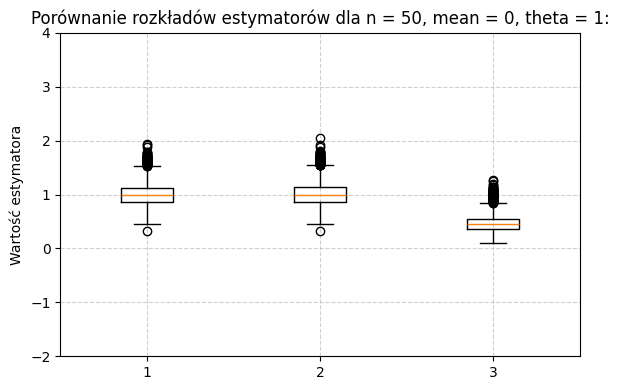

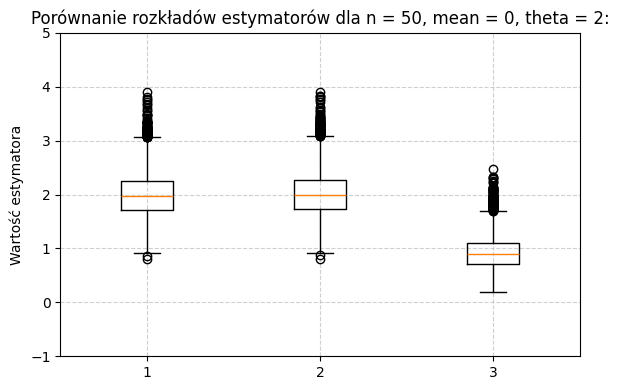

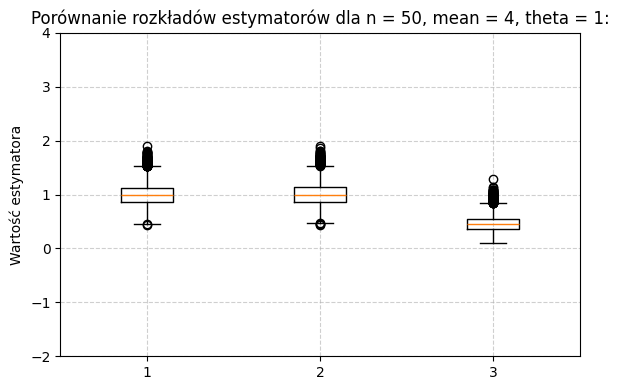

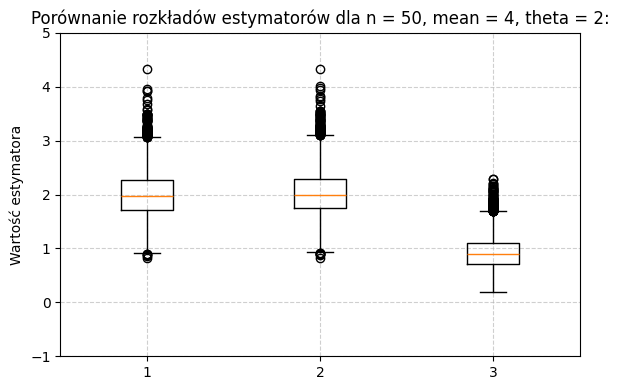

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

def estimator_1(x):
    x_mean = np.mean(x)
    return 1 / (len(x) - 1) * np.sum((x - x_mean) ** 2)

def estimator_2(x):
    x_median = np.median(x)
    return 1 / (len(x) - 1) * np.sum((x - x_median) ** 2)

def estimator_3(x):
    return np.median((x - np.mean(x)) ** 2)

n = 50
k = 10_000
labels = ['1', '2', '3']

cases = [
    (0, 1),
    (0, 2),
    (4, 1),
    (4, 2)
]

for mi, theta in cases:
    samples = np.random.normal(loc=mi, scale=np.sqrt(theta), size=(k, n))

    est_vals = [
        np.apply_along_axis(estimator_1, axis=1, arr=samples),
        np.apply_along_axis(estimator_2, axis=1, arr=samples),
        np.apply_along_axis(estimator_3, axis=1, arr=samples)
    ]
    fig, ax = plt.subplots(figsize=(6, 4))

    print(f"\nWyniki dla n = {n}, mean = {mi}, theta = {theta}:")
    print(f"{'Estymator':<20} | {'Obciążenie':<12} | {'Wariancja':<12} | {'MSE':<12} | {'Diff':<12}")
    print("-" * 75)

    for i, est_val in enumerate(est_vals):
        bias = np.mean(est_val) - theta
        variance = np.var(est_val)
        mse = np.mean((est_val -theta) ** 2)
        diff = np.abs(mse - bias ** 2 - variance)
        print(f"{labels[i]:<20} | {bias:<12.4f} | {variance:<12.4f} | {mse:<12.4f} | {diff:<12.4f}")

    ax.boxplot(est_vals, tick_labels=labels)
    ax.set_title(f'Porównanie rozkładów estymatorów dla n = {n}, mean = {mi}, theta = {theta}:')
    ax.set_ylabel('Wartość estymatora')
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.set_ylim(-3 + theta, 3 + theta)
    plt.tight_layout()
plt.show()